In [72]:
import pandas as pd
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [73]:
import mysql.connector

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="9012345100",
    database="healthcare_db",
    port=3306
)

if conn.is_connected():
    print("MySQL connected successfully!")

MySQL connected successfully!


In [74]:
query = "select * from healthcare_table"
df = pd.read_sql(query, conn)
df.head()

,patient_id,claim_id,admission_date,discharge_date,patient_age,gender,city,insurance_provider,department,diagnosis,...,claim_status,denial_reason,payment_days,payment_date,amount_collected,outstanding_amount,provider_experience_years,patient_satisfaction_score,followup_required,collection_rate_pct
0,P100000,C200000,2024-10-04,2024-10-10,85,Female,Noida,Medicaid,Neurology,Epilepsy,...,Paid,Not Applicable,31,2024-11-10,10410.67,711.14,4.9,3.6,No,93.61
1,P100001,C200001,2024-01-16,2024-01-20,45,Male,Gurugram,Employer,Pulmonology,Bronchitis,...,Paid,Not Applicable,14,2024-02-03,7088.53,669.35,12.7,4.3,No,91.37
2,P100002,C200002,2025-06-08,2025-06-19,1,Female,Gurugram,Private,Gynecology,Gynecological Infection,...,Paid,Not Applicable,20,2025-07-09,17196.52,1153.31,8.6,4.6,No,93.71
3,P100003,C200003,2024-12-21,2024-12-31,33,Male,Meerut,Medicaid,General Medicine,Hypertension,...,Paid,Not Applicable,34,2025-02-03,13552.18,1912.69,16.5,4.2,No,87.63
4,P100004,C200004,2024-12-21,2024-12-26,66,Male,Noida,Private,Cardiology,Hypertension,...,Paid,Not Applicable,44,2025-02-08,10860.35,397.98,10.1,5.0,No,96.47


In [75]:
df.tail()

,patient_id,claim_id,admission_date,discharge_date,patient_age,gender,city,insurance_provider,department,diagnosis,...,claim_status,denial_reason,payment_days,payment_date,amount_collected,outstanding_amount,provider_experience_years,patient_satisfaction_score,followup_required,collection_rate_pct
9995,P109995,C209995,2024-05-27,2024-05-29,13,Female,Bijnor,Self-Pay,Gastroenterology,Gastritis,...,Paid,Not Applicable,27,2024-06-25,4693.82,519.47,14.6,3.8,No,90.04
9996,P109996,C209996,2024-08-12,2024-08-18,31,Female,Chandigarh,Medicare,Gastroenterology,Gastritis,...,Paid,Not Applicable,30,2024-09-17,9868.08,755.04,8.3,3.4,No,92.89
9997,P109997,C209997,2024-04-14,2024-04-17,89,Male,Dehradun,Private,Pulmonology,COPD,...,Paid,Not Applicable,11,2024-04-28,7384.99,1117.83,17.1,4.0,No,86.85
9998,P109998,C209998,2025-07-09,2025-07-13,64,Female,Jaipur,Medicare,Neurology,Neuropathy,...,Paid,Not Applicable,7,2025-07-20,9394.16,1171.49,8.2,4.4,No,88.91
9999,P109999,C209999,2024-12-21,2024-12-22,26,Female,Gurugram,Self-Pay,Cardiology,Heart Failure,...,Paid,Not Applicable,11,2025-01-02,7110.21,1233.34,11.0,4.1,Yes,85.22


In [76]:
df.shape

(10000, 30)

In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   patient_id                  10000 non-null  object 
 1   claim_id                    10000 non-null  object 
 2   admission_date              10000 non-null  object 
 3   discharge_date              10000 non-null  object 
 4   patient_age                 10000 non-null  int64  
 5   gender                      10000 non-null  object 
 6   city                        10000 non-null  object 
 7   insurance_provider          10000 non-null  object 
 8   department                  10000 non-null  object 
 9   diagnosis                   10000 non-null  object 
 10  claim_type                  10000 non-null  object 
 11  length_of_stay_days         10000 non-null  int64  
 12  comorbidity_count           10000 non-null  int64  
 13  previous_visits             1000

In [78]:
df.isnull().sum()

patient_id                    0
claim_id                      0
admission_date                0
discharge_date                0
patient_age                   0
gender                        0
city                          0
insurance_provider            0
department                    0
diagnosis                     0
claim_type                    0
length_of_stay_days           0
comorbidity_count             0
previous_visits               0
readmission_30d               0
billed_amount                 0
allowed_amount                0
insurance_paid                0
patient_responsibility        0
submission_delay_days         0
claim_status                  0
denial_reason                 0
payment_days                  0
payment_date                  0
amount_collected              0
outstanding_amount            0
provider_experience_years     0
patient_satisfaction_score    0
followup_required             0
collection_rate_pct           0
dtype: int64

In [79]:
cols = ['admission_date','discharge_date','payment_date']
df[cols] = df[cols].apply(pd.to_datetime)

In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   patient_id                  10000 non-null  object        
 1   claim_id                    10000 non-null  object        
 2   admission_date              10000 non-null  datetime64[ns]
 3   discharge_date              10000 non-null  datetime64[ns]
 4   patient_age                 10000 non-null  int64         
 5   gender                      10000 non-null  object        
 6   city                        10000 non-null  object        
 7   insurance_provider          10000 non-null  object        
 8   department                  10000 non-null  object        
 9   diagnosis                   10000 non-null  object        
 10  claim_type                  10000 non-null  object        
 11  length_of_stay_days         10000 non-null  int64      

In [81]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
admission_date,10000,2024-12-30 22:55:03.360000,2024-01-01 00:00:00,2024-07-02 00:00:00,2025-01-02 00:00:00,2025-07-02 00:00:00,2025-12-30 00:00:00,NaN
discharge_date,10000,2025-01-04 04:17:36.960000,2024-01-02 00:00:00,2024-07-06 00:00:00,2025-01-06 00:00:00,2025-07-06 00:00:00,2026-01-07 00:00:00,NaN
patient_age,10000.0,47.2985,1.0,34.0,47.0,61.0,95.0,19.469343
length_of_stay_days,10000.0,4.224,1.0,2.0,4.0,6.0,25.0,2.875178
comorbidity_count,10000.0,1.4074,0.0,1.0,1.0,2.0,6.0,1.184131
previous_visits,10000.0,1.789,0.0,1.0,2.0,3.0,10.0,1.338379
billed_amount,10000.0,11794.097049,500.0,8586.07,11185.625,14353.095,36754.66,4467.163849
allowed_amount,10000.0,9106.935671,447.26,6521.3175,8559.47,11118.9075,31228.25,3617.072368
insurance_paid,10000.0,7656.335889,420.56,5388.12,7166.33,9360.26,27863.09,3156.370524
patient_responsibility,10000.0,1450.599782,26.7,699.2725,1270.865,1973.1075,7869.32,968.321796


In [82]:
print(df["claim_status"].value_counts())

claim_status
Paid      8354
Denied    1646
Name: count, dtype: int64


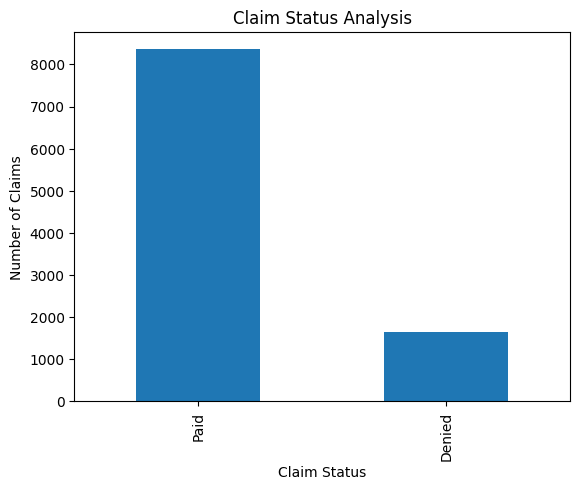

In [83]:
df["claim_status"].value_counts().plot(kind="bar")

plt.title("Claim Status Analysis")
plt.xlabel("Claim Status")
plt.ylabel("Number of Claims")
plt.show()

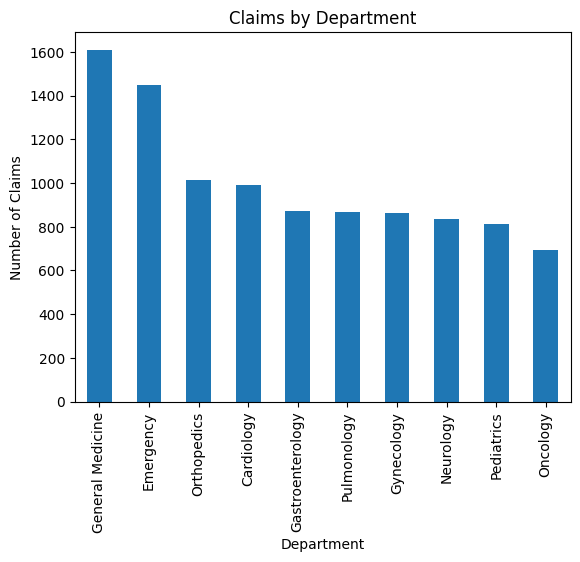

In [84]:
df["department"].value_counts().plot(kind="bar")

plt.title("Claims by Department")
plt.xlabel("Department")
plt.ylabel("Number of Claims")
plt.show()

In [85]:
df.columns

Index(['patient_id', 'claim_id', 'admission_date', 'discharge_date',
       'patient_age', 'gender', 'city', 'insurance_provider', 'department',
       'diagnosis', 'claim_type', 'length_of_stay_days', 'comorbidity_count',
       'previous_visits', 'readmission_30d', 'billed_amount', 'allowed_amount',
       'insurance_paid', 'patient_responsibility', 'submission_delay_days',
       'claim_status', 'denial_reason', 'payment_days', 'payment_date',
       'amount_collected', 'outstanding_amount', 'provider_experience_years',
       'patient_satisfaction_score', 'followup_required',
       'collection_rate_pct'],
      dtype='object')

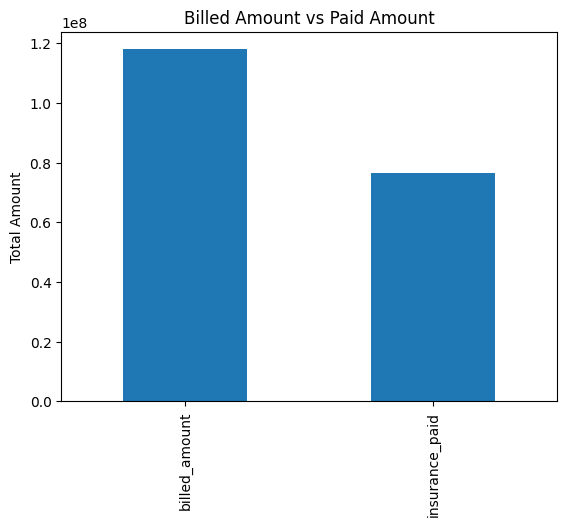

In [86]:
df[["billed_amount", "insurance_paid"]].sum().plot(kind="bar")
plt.title("Billed Amount vs Paid Amount")
plt.ylabel("Total Amount")
plt.show()

claim_status
Paid      83.54
Denied    16.46
Name: proportion, dtype: float64


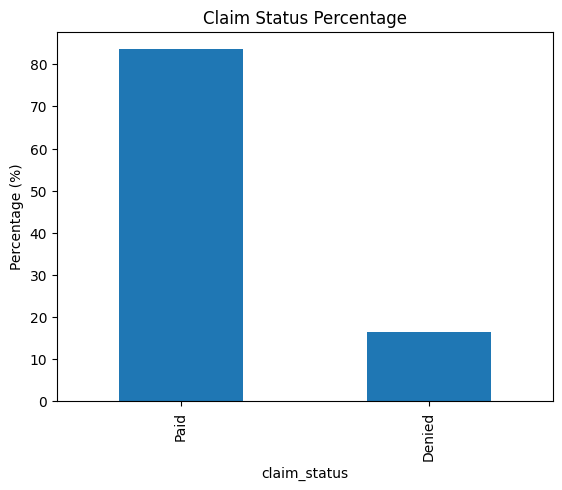

In [87]:
status = df["claim_status"].value_counts(normalize=True) * 100

print(status.round(2))

status.plot(kind="bar", title="Claim Status Percentage")
plt.ylabel("Percentage (%)")
plt.show()

department
General Medicine    252
Emergency           233
Orthopedics         173
Cardiology          162
Gynecology          158
Gastroenterology    146
Pulmonology         144
Pediatrics          132
Neurology           131
Oncology            115
Name: count, dtype: int64


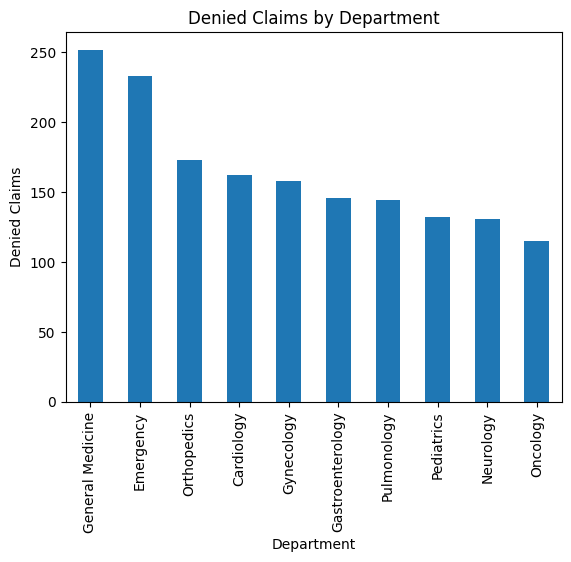

In [88]:
denial = df[df["claim_status"].str.lower() == "denied"]

print(denial["department"].value_counts())

denial["department"].value_counts().plot(kind="bar")
plt.title("Denied Claims by Department")
plt.xlabel("Department")
plt.ylabel("Denied Claims")
plt.show()

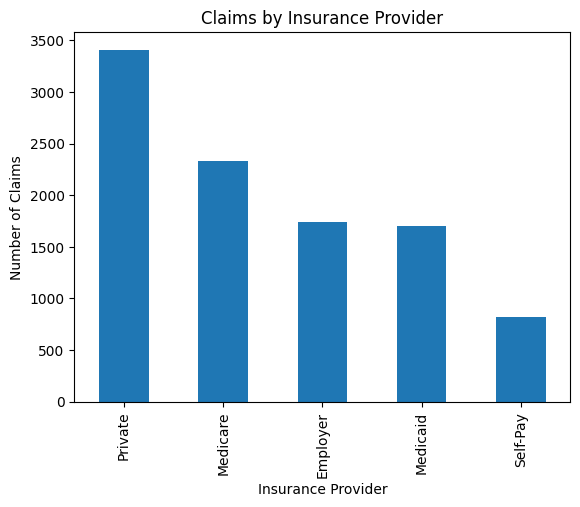

In [89]:
df["insurance_provider"].value_counts().plot(kind="bar")

plt.title("Claims by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Number of Claims")
plt.show()

In [90]:
print("Total Billed:", df["billed_amount"].sum())
print("Average Billed:", df["billed_amount"].mean())
print("Maximum Billed:", df["billed_amount"].max())
print("Minimum Billed:", df["billed_amount"].min())

Total Billed: 117940970.49
Average Billed: 11794.097049
Maximum Billed: 36754.66
Minimum Billed: 500.0


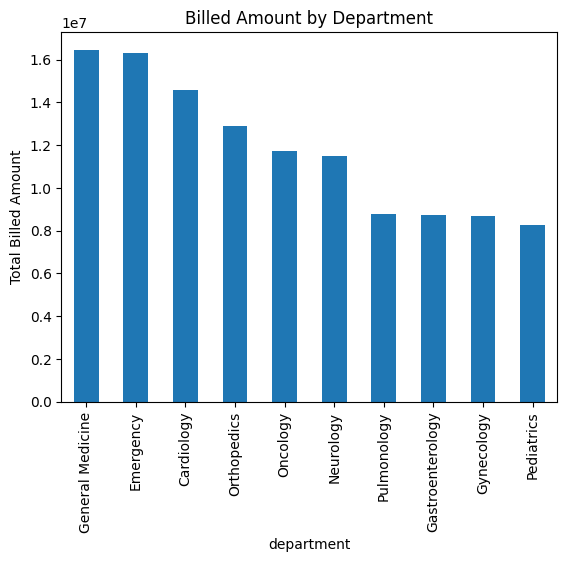

In [91]:
df.groupby("department")["billed_amount"].sum().sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Billed Amount by Department")
plt.ylabel("Total Billed Amount")
plt.show()

count    10000.000000
mean        47.298500
std         19.469343
min          1.000000
25%         34.000000
50%         47.000000
75%         61.000000
max         95.000000
Name: patient_age, dtype: float64


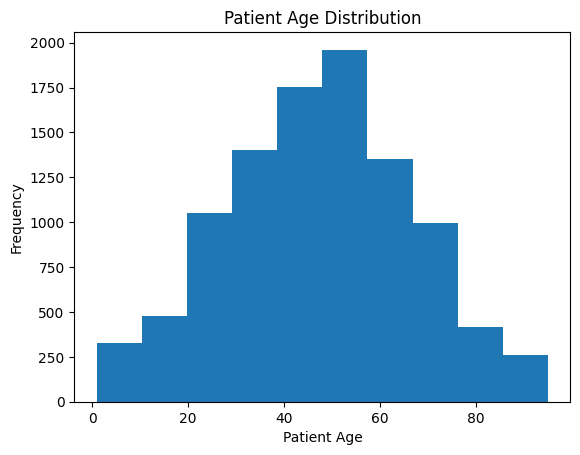

In [92]:
print(df["patient_age"].describe())


df["patient_age"].plot(kind="hist", bins=10)

plt.title("Patient Age Distribution")
plt.xlabel("Patient Age")
plt.show()

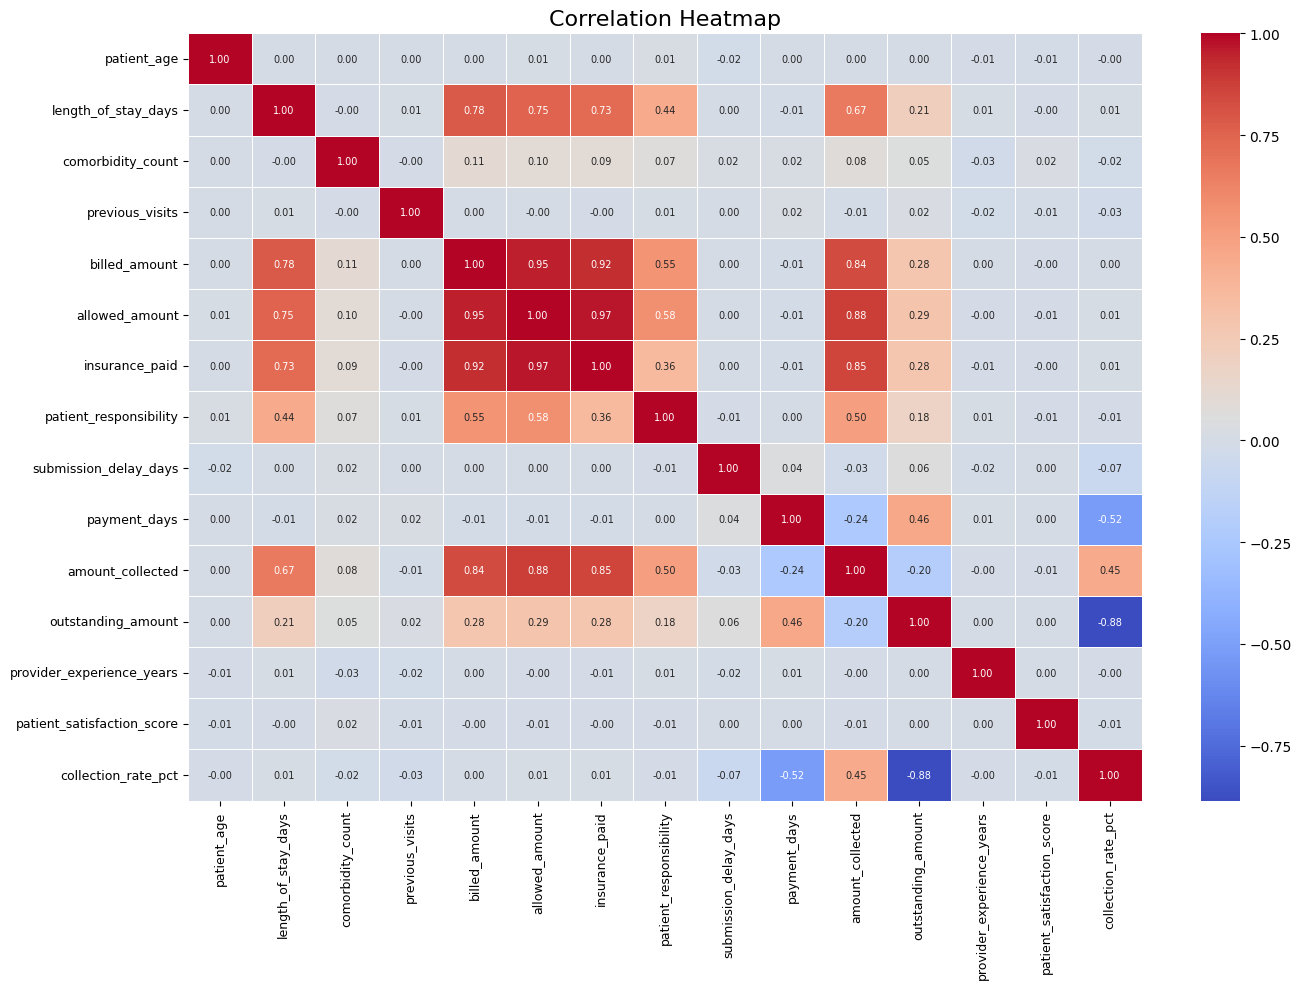

In [93]:
#numeric_df = df.select_dtypes(include="number")
numeric_df = df[[
       'patient_age', 'length_of_stay_days', 'comorbidity_count',
       'previous_visits', 'billed_amount', 'allowed_amount',
       'insurance_paid', 'patient_responsibility', 'submission_delay_days','payment_days', 
       'amount_collected', 'outstanding_amount', 'provider_experience_years',
       'patient_satisfaction_score',
       'collection_rate_pct']]
plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    annot_kws={"size": 7},
    linewidths=0.5
)

plt.title("Correlation Heatmap", fontsize=16)
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

Total Outstanding: 13189084.18
Average Outstanding: 1318.908418


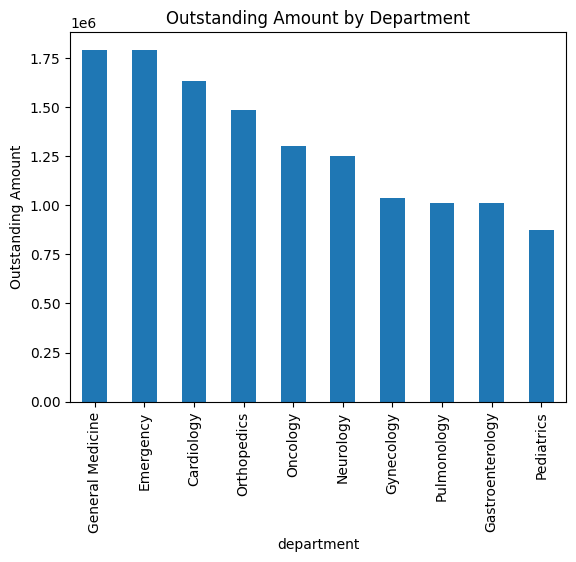

In [94]:
print("Total Outstanding:", df["outstanding_amount"].sum())
print("Average Outstanding:", df["outstanding_amount"].mean())

df.groupby("department")["outstanding_amount"].sum().sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Outstanding Amount by Department")
plt.ylabel("Outstanding Amount")
plt.show()

denial_reason
Duplicate Claim           292
Eligibility Issue         285
Coding Error              275
Missing Documentation     271
Incorrect Billing Code    264
Authorization Required    259
Name: count, dtype: int64


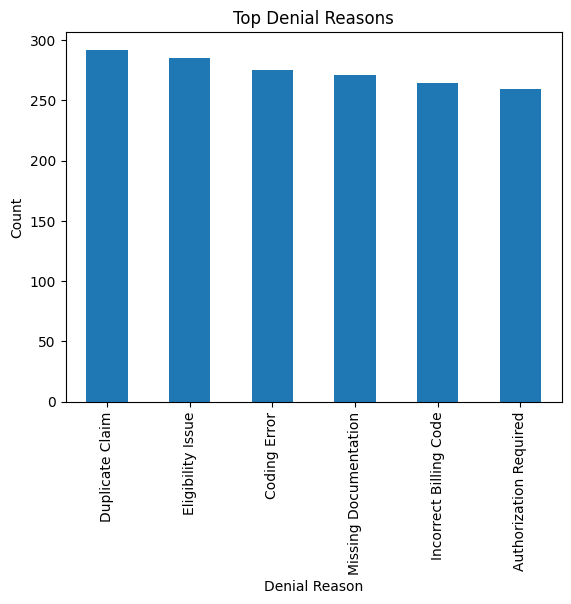

In [95]:
denial = df[df["claim_status"].str.lower() == "denied"]

print(denial["denial_reason"].value_counts())

denial["denial_reason"].value_counts().head(10).plot(kind="bar")

plt.title("Top Denial Reasons")
plt.xlabel("Denial Reason")
plt.ylabel("Count")
plt.show()

In [96]:
df2 = df.copy()

In [97]:
df2.drop(columns= ['patient_id', 'claim_id','admission_date','discharge_date','payment_date'],inplace=True)

In [98]:
df2.shape

(10000, 25)

In [99]:
df2.columns

Index(['patient_age', 'gender', 'city', 'insurance_provider', 'department',
       'diagnosis', 'claim_type', 'length_of_stay_days', 'comorbidity_count',
       'previous_visits', 'readmission_30d', 'billed_amount', 'allowed_amount',
       'insurance_paid', 'patient_responsibility', 'submission_delay_days',
       'claim_status', 'denial_reason', 'payment_days', 'amount_collected',
       'outstanding_amount', 'provider_experience_years',
       'patient_satisfaction_score', 'followup_required',
       'collection_rate_pct'],
      dtype='object')

In [100]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder,StandardScaler
label_encode_cols = ['gender','previous_visits','claim_status','denial_reason','followup_required','claim_type']
one_hot_encode = ['city','insurance_provider','department,diagnosis']
standardize = ['patient_age','length_of_stay_days','comorbidity_count','submission_delay_days','payment_days','amount_collected','outstanding_amount',
'provider_experience_years','patient_satisfaction_score','collection_rate_pct']

In [101]:
df2

,patient_age,gender,city,insurance_provider,department,diagnosis,claim_type,length_of_stay_days,comorbidity_count,previous_visits,...,submission_delay_days,claim_status,denial_reason,payment_days,amount_collected,outstanding_amount,provider_experience_years,patient_satisfaction_score,followup_required,collection_rate_pct
0,85,Female,Noida,Medicaid,Neurology,Epilepsy,Emergency,6,2,2,...,2,Paid,Not Applicable,31,10410.67,711.14,4.9,3.6,No,93.61
1,45,Male,Gurugram,Employer,Pulmonology,Bronchitis,Outpatient,4,0,1,...,7,Paid,Not Applicable,14,7088.53,669.35,12.7,4.3,No,91.37
2,1,Female,Gurugram,Private,Gynecology,Gynecological Infection,Inpatient,11,2,0,...,7,Paid,Not Applicable,20,17196.52,1153.31,8.6,4.6,No,93.71
3,33,Male,Meerut,Medicaid,General Medicine,Hypertension,Inpatient,10,3,2,...,3,Paid,Not Applicable,34,13552.18,1912.69,16.5,4.2,No,87.63
4,66,Male,Noida,Private,Cardiology,Hypertension,Outpatient,5,4,0,...,4,Paid,Not Applicable,44,10860.35,397.98,10.1,5.0,No,96.47
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,13,Female,Bijnor,Self-Pay,Gastroenterology,Gastritis,Inpatient,2,2,1,...,6,Paid,Not Applicable,27,4693.82,519.47,14.6,3.8,No,90.04
9996,31,Female,Chandigarh,Medicare,Gastroenterology,Gastritis,Inpatient,6,0,1,...,5,Paid,Not Applicable,30,9868.08,755.04,8.3,3.4,No,92.89
9997,89,Male,Dehradun,Private,Pulmonology,COPD,Outpatient,3,0,1,...,5,Paid,Not Applicable,11,7384.99,1117.83,17.1,4.0,No,86.85
9998,64,Female,Jaipur,Medicare,Neurology,Neuropathy,Emergency,4,1,1,...,4,Paid,Not Applicable,7,9394.16,1171.49,8.2,4.4,No,88.91


In [102]:
cols_to_scale = [
    'patient_age', 'length_of_stay_days', 'comorbidity_count', 
    'submission_delay_days', 'payment_days', 'amount_collected', 
    'outstanding_amount', 'provider_experience_years', 
    'patient_satisfaction_score', 'collection_rate_pct','billed_amount','allowed_amount','insurance_paid','patient_responsibility'
]

scaler = StandardScaler()
df2[cols_to_scale] = scaler.fit_transform(df2[cols_to_scale])

print("Standardization successfully ")

Standardization successfully 


In [103]:
df2

,patient_age,gender,city,insurance_provider,department,diagnosis,claim_type,length_of_stay_days,comorbidity_count,previous_visits,...,submission_delay_days,claim_status,denial_reason,payment_days,amount_collected,outstanding_amount,provider_experience_years,patient_satisfaction_score,followup_required,collection_rate_pct
0,1.936552,Female,Noida,Medicaid,Neurology,Epilepsy,Emergency,0.617732,0.500477,2,...,-1.039310,Paid,Not Applicable,0.943624,0.744132,-0.346143,-0.872454,-0.574785,No,0.472595
1,-0.118063,Male,Gurugram,Employer,Pulmonology,Bronchitis,Outpatient,-0.077912,-1.188611,1,...,0.691893,Paid,Not Applicable,-0.766624,-0.198471,-0.369944,0.759487,0.497061,No,0.342502
2,-2.378140,Female,Gurugram,Private,Gynecology,Gynecological Infection,Inpatient,2.356841,0.500477,0,...,0.691893,Paid,Not Applicable,-0.163007,2.669505,-0.094314,-0.098329,0.956424,No,0.478403
3,-0.734448,Male,Meerut,Medicaid,General Medicine,Hypertension,Inpatient,2.009019,1.345020,2,...,-0.693070,Paid,Not Applicable,1.245433,1.635484,0.338177,1.554535,0.343940,No,0.125295
4,0.960609,Male,Noida,Private,Cardiology,Hypertension,Outpatient,0.269910,2.189564,0,...,-0.346829,Paid,Not Applicable,2.251461,0.871721,-0.524498,0.215506,1.568907,No,0.638695
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,-1.761755,Female,Bijnor,Self-Pay,Gastroenterology,Gastritis,Inpatient,-0.773556,0.500477,1,...,0.345652,Paid,Not Applicable,0.541213,-0.877931,-0.455306,1.157011,-0.268543,No,0.265260
9996,-0.837178,Female,Chandigarh,Medicare,Gastroenterology,Gastritis,Inpatient,0.617732,-1.188611,1,...,-0.000589,Paid,Not Applicable,0.843022,0.590181,-0.321141,-0.161096,-0.881027,No,0.430780
9997,2.142013,Male,Dehradun,Private,Pulmonology,COPD,Outpatient,-0.425734,-1.188611,1,...,-0.000589,Paid,Not Applicable,-1.068432,-0.114355,-0.114521,1.680069,0.037698,No,0.079995
9998,0.857879,Female,Jaipur,Medicare,Neurology,Neuropathy,Emergency,-0.077912,-0.344067,1,...,-0.346829,Paid,Not Applicable,-1.470844,0.455714,-0.083959,-0.182018,0.650182,No,0.199633


In [104]:
label_encode_cols = ['gender', 'previous_visits', 'claim_status', 'denial_reason', 'claim_type','followup_required']

le = LabelEncoder()

for col in label_encode_cols:
    if col in df2.columns:
        df2[col] = le.fit_transform(df2[col])

print("Encoding successfully!")

Encoding successfully!


In [105]:
df2

,patient_age,gender,city,insurance_provider,department,diagnosis,claim_type,length_of_stay_days,comorbidity_count,previous_visits,...,submission_delay_days,claim_status,denial_reason,payment_days,amount_collected,outstanding_amount,provider_experience_years,patient_satisfaction_score,followup_required,collection_rate_pct
0,1.936552,0,Noida,Medicaid,Neurology,Epilepsy,0,0.617732,0.500477,2,...,-1.039310,1,6,0.943624,0.744132,-0.346143,-0.872454,-0.574785,0,0.472595
1,-0.118063,1,Gurugram,Employer,Pulmonology,Bronchitis,2,-0.077912,-1.188611,1,...,0.691893,1,6,-0.766624,-0.198471,-0.369944,0.759487,0.497061,0,0.342502
2,-2.378140,0,Gurugram,Private,Gynecology,Gynecological Infection,1,2.356841,0.500477,0,...,0.691893,1,6,-0.163007,2.669505,-0.094314,-0.098329,0.956424,0,0.478403
3,-0.734448,1,Meerut,Medicaid,General Medicine,Hypertension,1,2.009019,1.345020,2,...,-0.693070,1,6,1.245433,1.635484,0.338177,1.554535,0.343940,0,0.125295
4,0.960609,1,Noida,Private,Cardiology,Hypertension,2,0.269910,2.189564,0,...,-0.346829,1,6,2.251461,0.871721,-0.524498,0.215506,1.568907,0,0.638695
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,-1.761755,0,Bijnor,Self-Pay,Gastroenterology,Gastritis,1,-0.773556,0.500477,1,...,0.345652,1,6,0.541213,-0.877931,-0.455306,1.157011,-0.268543,0,0.265260
9996,-0.837178,0,Chandigarh,Medicare,Gastroenterology,Gastritis,1,0.617732,-1.188611,1,...,-0.000589,1,6,0.843022,0.590181,-0.321141,-0.161096,-0.881027,0,0.430780
9997,2.142013,1,Dehradun,Private,Pulmonology,COPD,2,-0.425734,-1.188611,1,...,-0.000589,1,6,-1.068432,-0.114355,-0.114521,1.680069,0.037698,0,0.079995
9998,0.857879,0,Jaipur,Medicare,Neurology,Neuropathy,0,-0.077912,-0.344067,1,...,-0.346829,1,6,-1.470844,0.455714,-0.083959,-0.182018,0.650182,0,0.199633


In [106]:
print(df2.columns)

Index(['patient_age', 'gender', 'city', 'insurance_provider', 'department',
       'diagnosis', 'claim_type', 'length_of_stay_days', 'comorbidity_count',
       'previous_visits', 'readmission_30d', 'billed_amount', 'allowed_amount',
       'insurance_paid', 'patient_responsibility', 'submission_delay_days',
       'claim_status', 'denial_reason', 'payment_days', 'amount_collected',
       'outstanding_amount', 'provider_experience_years',
       'patient_satisfaction_score', 'followup_required',
       'collection_rate_pct'],
      dtype='object')


In [107]:
one_hot_cols = ['city', 'insurance_provider', 'department', 'diagnosis']

df2 = pd.get_dummies(df2, columns=one_hot_cols, drop_first=True)

print("One-Hot Encoding successfully ")

One-Hot Encoding successfully 


In [108]:
df2['readmission_30d'] = df2['readmission_30d'].map({
    'Yes': 1,
    'No': 0
})

In [109]:
df2

,patient_age,gender,claim_type,length_of_stay_days,comorbidity_count,previous_visits,readmission_30d,billed_amount,allowed_amount,insurance_paid,...,diagnosis_Liver Disorder,diagnosis_Lung Cancer,diagnosis_Lymphoma,diagnosis_Migraine,diagnosis_Neuropathy,diagnosis_PCOS,diagnosis_Pneumonia,diagnosis_Pregnancy,diagnosis_Respiratory Distress,diagnosis_Stroke
0,1.936552,0,0,0.617732,0.500477,2,0,1.054626,0.557073,0.967322,...,False,False,False,False,False,False,False,False,False,False
1,-0.118063,1,2,-0.077912,-1.188611,1,0,-0.742111,-0.372988,-0.424942,...,False,False,False,False,False,False,False,False,False,False
2,-2.378140,0,1,2.356841,0.500477,0,0,2.128218,2.555480,3.087186,...,False,False,False,False,False,False,False,False,False,False
3,-0.734448,1,1,2.009019,1.345020,2,0,1.994137,1.757845,1.167717,...,False,False,False,False,False,False,False,False,False,False
4,0.960609,1,2,0.269910,2.189564,0,0,0.410635,0.594819,0.784609,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,-1.761755,0,1,-0.773556,0.500477,1,0,-1.295842,-1.076517,-1.110954,...,False,False,False,False,False,False,False,False,False,False
9996,-0.837178,0,1,0.617732,-1.188611,1,0,0.213061,0.419195,0.486645,...,False,False,False,False,False,False,False,False,False,False
9997,2.142013,1,2,-0.425734,-1.188611,1,0,-0.209577,-0.167026,0.129419,...,False,False,False,False,False,False,False,False,False,False
9998,0.857879,0,0,-0.077912,-0.344067,1,0,0.055636,0.403306,-0.014025,...,False,False,False,False,True,False,False,False,False,False


In [110]:
df2 = df2.astype(int)

# CLAIM DENIAL PREDICTION

In [111]:
X = df2.drop(columns=['claim_status','patient_age','length_of_stay_days','comorbidity_count','billed_amount',
                      'allowed_amount','provider_experience_years','outstanding_amount' ,'amount_collected','insurance_paid'
                      ,'patient_satisfaction_score','provider_experience_years','denial_reason','payment_days',
                      'patient_responsibility',"gender",'previous_visits','readmission_30d'],axis= 1,errors='ignore')

 
y =df2["claim_status"]


In [112]:
# X.to_csv("X.csv", index=False)

In [113]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42 )

from sklearn.linear_model import LogisticRegression

# Cross-validation se 5 alag-alag folds par accuracy check karein
lr = LogisticRegression(C=0.1, max_iter=1000, random_state=42)
scores = cross_val_score(lr, X, y, cv=5, scoring='accuracy')

print("Cross-Validation Accuracies:", scores)
print(f"Mean Accuracy: {scores.mean():.4f}")
lr.fit(X_train,y_train)

Cross-Validation Accuracies: [0.978  0.9785 0.978  0.981  0.972 ]
Mean Accuracy: 0.9775


,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [114]:
y_pred_lr = lr.predict(X_test)

In [115]:
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report,r2_score
print(accuracy_score(y_pred_lr,y_test))
print(classification_report(y_pred_lr,y_test))
print(confusion_matrix(y_pred_lr,y_test))
train_acc = lr.score(X_train, y_train)
test_acc = lr.score(X_test, y_test)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Testing Accuracy:  {test_acc:.4f}")

0.983
              precision    recall  f1-score   support

           0       0.89      1.00      0.94       277
           1       1.00      0.98      0.99      1723

    accuracy                           0.98      2000
   macro avg       0.95      0.99      0.97      2000
weighted avg       0.98      0.98      0.98      2000

[[ 277    0]
 [  34 1689]]
Training Accuracy: 0.9761
Testing Accuracy:  0.9830


In [116]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=8,criterion='gini',
    splitter='best',
    min_samples_split=4,
    min_samples_leaf=5,
    
    random_state=42,
    max_leaf_nodes=5,
    
    ccp_alpha=0.1,)
dt.fit(X_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",4
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",5
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",0.1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more

In [117]:
pred_dt = dt.predict(X_test)
print(accuracy_score(pred_dt,y_test))
print(classification_report(pred_dt,y_test))
print(confusion_matrix(pred_dt,y_test))
train_acc1 = dt.score(X_train, y_train)
test_acc2 = dt.score(X_test, y_test)

print(f"Training Accuracy: {train_acc1:.4f}")
print(f"Testing Accuracy:  {test_acc2:.4f}")

0.983
              precision    recall  f1-score   support

           0       0.89      1.00      0.94       277
           1       1.00      0.98      0.99      1723

    accuracy                           0.98      2000
   macro avg       0.95      0.99      0.97      2000
weighted avg       0.98      0.98      0.98      2000

[[ 277    0]
 [  34 1689]]
Training Accuracy: 0.9761
Testing Accuracy:  0.9830


In [118]:
df2['claim_status'].value_counts()

claim_status
1    8354
0    1646
Name: count, dtype: int64

In [119]:
from scipy.stats import chi2_contingency
import pandas as pd

# 1. selected_features ki list (single bracket ke sath)
selected_features = ['claim_status','patient_age','length_of_stay_days','comorbidity_count','billed_amount',
                      'allowed_amount','provider_experience_years','outstanding_amount' ,'amount_collected','insurance_paid'
                      ,'patient_satisfaction_score','provider_experience_years',
                      'patient_responsibility',"gender",'previous_visits','readmission_30d']
# (Note: Chi-square ke liye sirf categorical/binary columns sabse behtar hote hain)

chi2_results = {} 
alpha = 0.008

# Maan lijiye aapka target variable 'claim_status' hai
target_col = 'claim_status'

for col in selected_features:
    if col in df.columns and target_col in df.columns:
        # Contingency table banayein
        contingency = pd.crosstab(df[col], df[target_col])
        
        # Chi2 test run karein
        chi2_stat, p_val, dof, ex = chi2_contingency(contingency) 
        
        # Decision lein
        decision = 'REJECT NULL (KEEP FEATURE)' if p_val < alpha else 'ACCEPT NULL (DROP FEATURE)' 
        
        # Results dictionary mein store karein
        chi2_results[col] = {
            'Chi_Statistics': chi2_stat, 
            'p_value': p_val, 
            'Decision': decision
        }

# Results ko DataFrame mein convert karke dekhein
results_df = pd.DataFrame.from_dict(chi2_results, orient='index')
print(results_df)

                            Chi_Statistics   p_value  \
claim_status                   9992.728957  0.000000   
patient_age                      89.687106  0.606673   
length_of_stay_days              20.911174  0.526233   
comorbidity_count                11.982623  0.062358   
billed_amount                  9981.819086  0.450740   
allowed_amount                 9974.546721  0.465538   
provider_experience_years       215.270394  0.841212   
outstanding_amount             9989.091452  0.097319   
amount_collected               9981.819086  0.450740   
insurance_paid                 9960.001990  0.458602   
patient_satisfaction_score       42.916840  0.232435   
patient_responsibility         9814.554680  0.505064   
gender                            0.030118  0.862222   
previous_visits                  11.481040  0.244171   
readmission_30d                   0.837288  0.360173   

                                              Decision  
claim_status                REJECT NULL (KEEP 

In [165]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import joblib
import os

# Lightweight Random Forest model
model = RandomForestClassifier(
    n_estimators=1,
    criterion='entropy',
    max_depth=3,
     min_samples_split=3,
    min_samples_leaf=3,
    max_features="log2",
    random_state=42,
    
    n_jobs=1
)

# Train model
model.fit(X_train, y_train)

# Check performance
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

# Save lightweight model
joblib.dump(
    model,
    "random_forest_model_compressed.pkl",
    compress=3
)

print(
    "Model size (MB):",
    round(os.path.getsize("random_forest_model_compressed.pkl") / (1024 * 1024), 2)
)

Accuracy: 0.8515
Model size (MB): 0.0


In [164]:
train_acc_rf = model.score(X_train, y_train)
test_acc_rf = accuracy_score(y_test, y_pred)

print(f"Random Forest Training Accuracy: {train_acc_rf:.4f}")
print(f"Random Forest Testing Accuracy:  {test_acc_rf:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Random Forest Training Accuracy: 0.8431
Random Forest Testing Accuracy:  0.8515

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.11      0.19       311
           1       0.86      0.99      0.92      1689

    accuracy                           0.85      2000
   macro avg       0.74      0.55      0.55      2000
weighted avg       0.82      0.85      0.80      2000

Confusion Matrix:
[[  34  277]
 [  20 1669]]


In [ ]:
# import joblib
# import os

# joblib.dump(
#     model,
#     "random_forest_light.pkl",
#     compress=3
# )

# size_mb = os.path.getsize("random_forest_light.pkl") / (1024 * 1024)

# print("Light model saved successfully!")
# print(f"Model size: {size_mb:.3f} MB")
# print("File path:", os.path.abspath("random_forest_light.pkl"))